# FAST: compressing action chunks into a few tokens ⚡
### Frequency-space Action Sequence Tokenisation (π0-FAST), step by step

**Code:** `src/Halo_VLA/pi_family/tokenizers.py` (`FastActionTokenizer`), `src/Halo_VLA/vla_foundations/fast_policy.py` (`FastActionPolicy`) ·
**paper:** Pertsch et al., *FAST: Efficient Action Tokenization for Vision-Language-Action Models*, 2025 ([arXiv:2501.09747](https://arxiv.org/abs/2501.09747)). Companion to `action_representations_step_by_step.ipynb` (read Part 1 there first: RT-2's per-step bins).

**The problem FAST solves.** RT-2 / OpenVLA write each action dimension at each time step as one token. For a **chunk** of `H` steps at a high control rate that is `H·D` tokens, which (i) makes decoding slow, and (ii) makes *learning* hard: neighbouring tokens are almost identical, so next-token prediction can be solved by
**copying the previous token** and the loss carries little signal about the plan. FAST compresses the chunk first, so that each token carries real information:

1. **DCT** along time, separately for every action dimension: smooth chunks put almost all their energy in a few low-frequency coefficients;
2. **quantise**: `round(scale · coefficient)`: most high-frequency values become 0;
3. **flatten** low-frequency first (all dimensions of coefficient 0, then of coefficient 1, …);
4. **byte-pair encoding** of the integer sequence: frequent pairs (above all runs of zeros) are merged into single tokens.

Decoding is the exact inverse (BPE undone, `÷ scale`, inverse DCT), so the *only* loss is the rounding in step 2.

### Where this notebook corrects the usual summary
* FAST is **DCT + quantisation + BPE**, not "DCT then tokenise the coefficients": the BPE stage is what turns thousands of integers into a handful of tokens. The paper also trains a **universal tokenizer, FAST+** (vocabulary 1024) on ~1M real robot trajectories, which is what π0-FAST uses.
* FAST is *one* answer to "OpenVLA is slow", not *the* answer. **OpenVLA-OFT** (Kim et al., 2025, "Optimizing Speed and Success") gets its speed-up differently: parallel decoding with bidirectional attention, action chunking, and a **continuous** L1-regression action head, i.e. no action tokens at all. π0 uses a flow-matching expert instead. (And "OFT" there is *not* "orthogonal fine-tuning": see the fine-tuning notebook.)
* FAST helps most where per-step binning is *worst*: **high-frequency control**. At 10 Hz-like rates binning is fine; the notebook measures both regimes (Step 7) and the honest result is that FAST does **not** win at the low rate.

| | published | this notebook |
|---|---|---|
| control rate / chunk | up to 50 Hz, chunks of 50 steps × 7 dims | two toy worlds: `H = 16` (coarse) and `H = 64` (4× finer steps) |
| tokenizer | FAST+ (BPE, vocabulary 1024) | our own BPE (≤ 48 merges) on 2-D actions |
| VLM | PaliGemma 3B | 318K-parameter toy VLM |

## Step 0: Setup: two control rates

The point world twice. `world` moves 0.05 per unit action (a chunk of 16 actions crosses the table). `hf_world` moves **0.0125**, i.e. the *same trajectories sampled four times as finely* (a 4× faster controller): a chunk of **64** actions covers the same ground. Everything else (VLM, task) is identical, so the only thing that changes is how
redundant neighbouring actions are.

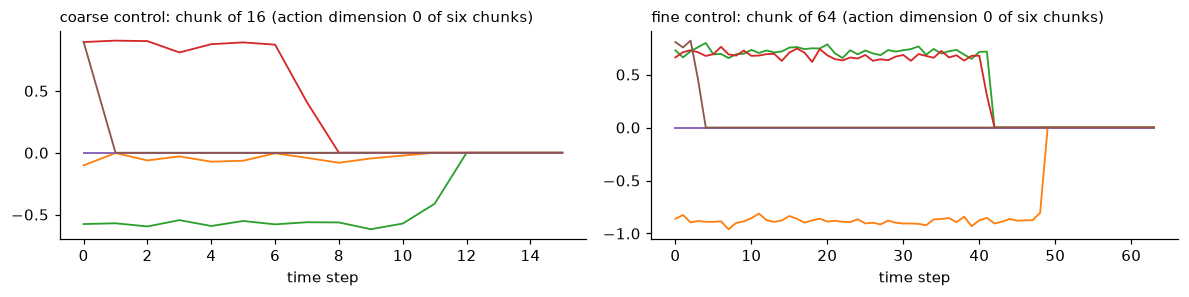

In [1]:
import time, numpy as np, torch
import matplotlib.pyplot as plt
import fnd_kit
fnd_kit.setup_paths()
from fnd_kit import plots, diagrams as dg

from open_vlas import (EMBODIMENTS, EmbodiedEvaluator, EmbodiedMixture, EmbodiedSource, ToyVLM, VLMConfig, VLMPretrainer, make_embodied_scenarios, make_reach_demos)
from pi_family import PiTrainer, PiVocabulary
from pi_family.tokenizers import FastActionTokenizer, dct_matrix
from pi_family.toy import DemoGenerator, PointWorld
from vla_foundations.autoregressive import ARConfig, AutoregressiveActionPolicy
from vla_foundations.discretization import ActionBinner
from vla_foundations.fast_policy import FastActionPolicy

torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110})
world, hf_world = PointWorld(), PointWorld(max_step=0.0125)
gen, hf_gen = DemoGenerator(world), DemoGenerator(hf_world, idle_steps=64, max_steps=400)
demos, hf_demos = make_reach_demos(gen, 3000, np.random.default_rng(0)), make_reach_demos(hf_gen, 3000, np.random.default_rng(0))
H_LO, H_HI = 16, 64
data_lo = EmbodiedMixture([EmbodiedSource(world, demos, EMBODIMENTS["point2d"], chunk_size=H_LO)])
data_hi = EmbodiedMixture([EmbodiedSource(hf_world, hf_demos, EMBODIMENTS["point2d"], chunk_size=H_HI)])
chunks_lo = data_lo.sample(1500, np.random.default_rng(0)).actions[:, :, :2]      # (N, 16, 2)
chunks_hi = data_hi.sample(1500, np.random.default_rng(0)).actions[:, :, :2]      # (N, 64, 2)
fig, axes = plt.subplots(1, 2, figsize=(11, 2.8))
for ax, ch, h, name in zip(axes, (chunks_lo, chunks_hi), (H_LO, H_HI), ("coarse control: chunk of 16", "fine control: chunk of 64")):
    for i in range(6):
        ax.plot(ch[i, :, 0], lw=1.2)
    ax.set_title(f"{name} (action dimension 0 of six chunks)", fontsize=9.5, loc="left"); ax.set_xlabel("time step"); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

### 🖼️ Diagram: the FAST pipeline on one real chunk (coarse world)
Read it left to right and top to bottom. ① the chunk; ② its DCT coefficients: the large ones are at the **low** frequencies (the abrupt stop, where the chunk drops to zero, adds a few high-frequency terms); ③ the rounded integers: mostly zeros; ④ the integers flattened low-frequency first;
⑤ after BPE: the long zero runs have been merged into single (purple) tokens.

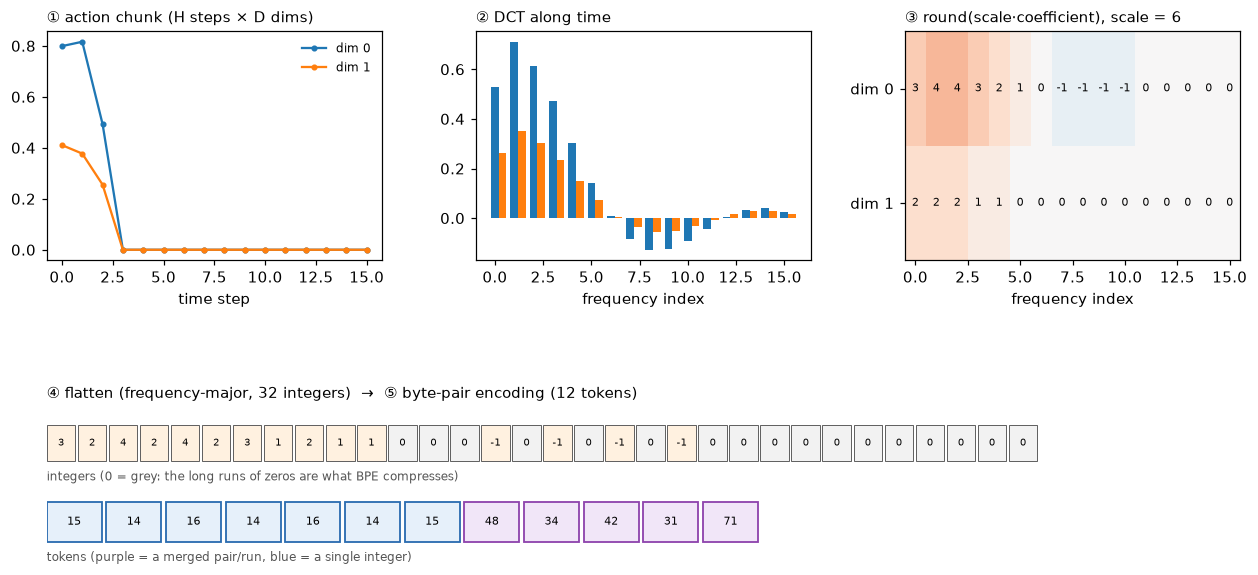

32 per-step bin tokens  →  12 FAST tokens for this chunk


In [2]:
moving = [i for i in range(len(chunks_lo)) if chunks_lo[i].abs().sum() > 3.0]       # skip the all-zero chunks taken after the task is done
i0 = moving[3]
tok_demo = FastActionTokenizer(H_LO, 2).fit(chunks_lo)
dg.fig_fast_pipeline(chunks_lo[i0], tok_demo)
plt.show()
print(f"{H_LO * 2} per-step bin tokens  →  {len(tok_demo.encode(chunks_lo[i0]))} FAST tokens for this chunk")

# Part 1: Why per-step binning struggles at high frequency

## Step 1: The copy baseline

RT-2 style tokenisation turns the chunk into `H·D` bin ids, time-major. Look at the sequence for dimension 0 and ask how much of it a model could predict *without looking at the image at all*: just by **repeating the previous token**.

coarse (H=16): a model that just copies the previous token is right for 88% of the tokens; only 1.8 of 16 tokens per chunk per dimension are 'new'
fine   (H=64): a model that just copies the previous token is right for 94% of the tokens; only 3.9 of 64 tokens per chunk per dimension are 'new'


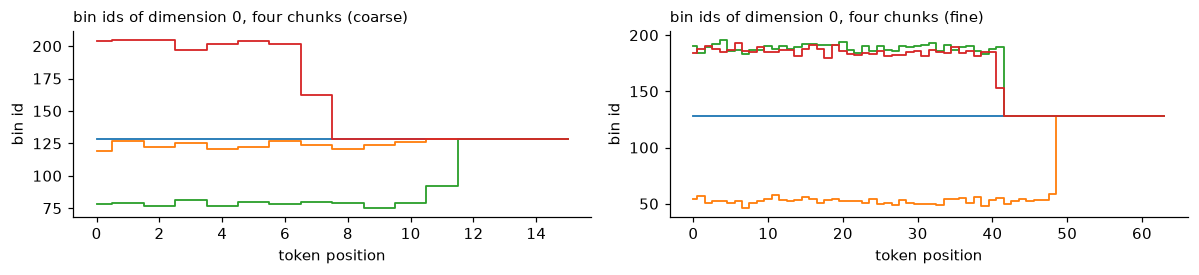

In [3]:
def copy_stats(chunks, num_bins=256, tolerance=5):
    b = ActionBinner(num_bins, -1.5, 1.5).encode(chunks[:, :, 0])           # (N, H) bin ids of dimension 0
    same = ((b[:, 1:] - b[:, :-1]).abs() <= tolerance).float()               # token equals its predecessor up to ±5 bins (±0.06: the demonstrations carry a little noise)
    informative = (1 - same).sum(1)                                          # tokens that the copy rule gets wrong
    return float(same.mean()), float(informative.mean()), b
for name, ch in (("coarse (H=16)", chunks_lo), ("fine   (H=64)", chunks_hi)):
    p_copy, n_new, b = copy_stats(ch)
    print(f"{name}: a model that just copies the previous token is right for {p_copy:.0%} of the tokens; only {n_new:.1f} of {ch.shape[1]} tokens per chunk per dimension are 'new'")
fig, axes = plt.subplots(1, 2, figsize=(11, 2.6))
for ax, ch, name in zip(axes, (chunks_lo, chunks_hi), ("coarse", "fine")):
    _, _, b = copy_stats(ch)
    for i in range(4):
        ax.step(range(b.shape[1]), b[i], where="mid", lw=1.2)
    ax.set_title(f"bin ids of dimension 0, four chunks ({name})", fontsize=9.5, loc="left"); ax.set_xlabel("token position"); ax.set_ylabel("bin id"); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

In **both** worlds **about 9 tokens in 10 are a copy of their predecessor** (88 % at the coarse rate, 94 % at the fine rate, up to ±5 bins): the sequence is a few *plateaus* with a handful of jumps (the start, the direction, the stop), not `H` independent decisions. Our demonstrator moves at a constant *normalised* speed, so the redundancy *per token* is the same at both rates; what the finer rate changes is the **length**: the same motion now needs 4× as many tokens.
(On a real robot the finer rate is also smoother step to step, which makes the redundancy even larger.) Two consequences, both from the FAST paper's analysis:

* the **loss is dominated by trivial tokens**: it can be driven low (token accuracy 0.7+) by a model that has only learned to copy, while the few informative tokens (the direction of the plan, when to stop) receive a small share of the gradient;
* decoding still has to emit all `H·D` of them, **sequentially**, and that number grows linearly with the control frequency.

The remedy is to represent the chunk in a basis where each number matters.

# Part 2: The pipeline, built from scratch

## Step 2: The DCT, by hand

The **Discrete Cosine Transform** (type II) writes a length-`N` signal as a sum of cosines of increasing frequency:
$$X_k = \sqrt{\tfrac{2}{N}}\,c_k \sum_{n=0}^{N-1} x_n \cos\!\Big(\tfrac{\pi}{N}\big(n+\tfrac12\big)k\Big),\qquad c_0=\tfrac1{\sqrt2},\; c_{k>0}=1 .$$
With this normalisation the transform matrix `D` is **orthonormal** (`D Dᵀ = I`), so it is lossless and energy-preserving; `X_0` is proportional to the mean (the "DC" term), `X_1` to the slope, and so on. We implement the sum literally, check it against the library matrix, and look at the basis.

literal sum == matrix product: True
orthonormal (D Dᵀ = I): True | lossless round trip: True
energy preserved (Parseval): 0.3762 = 0.3762


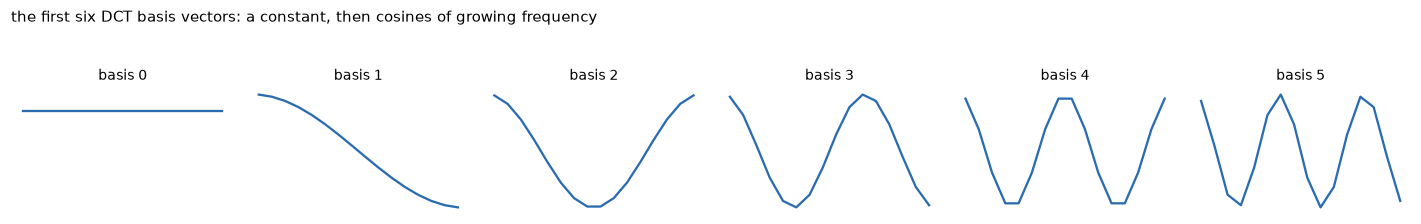

In [4]:
def dct_by_definition(x):
    n = len(x)
    out = np.zeros(n)
    for k in range(n):
        ck = 1 / np.sqrt(2) if k == 0 else 1.0
        out[k] = np.sqrt(2 / n) * ck * sum(x[i] * np.cos(np.pi / n * (i + 0.5) * k) for i in range(n))
    return out

x = chunks_lo[i0, :, 1].numpy()
D = dct_matrix(H_LO)
print("literal sum == matrix product:", np.allclose(dct_by_definition(x), (D @ torch.from_numpy(x)).numpy(), atol=1e-5))
print("orthonormal (D Dᵀ = I):", torch.allclose(D @ D.T, torch.eye(H_LO), atol=1e-5), "| lossless round trip:", torch.allclose(D.T @ (D @ torch.from_numpy(x)), torch.from_numpy(x), atol=1e-5))
print("energy preserved (Parseval):", round(float((x ** 2).sum()), 4), "=", round(float(((D @ torch.from_numpy(x)) ** 2).sum()), 4))
fig, axes = plt.subplots(1, 6, figsize=(13, 1.9), sharey=True)
for k, ax in enumerate(axes):
    ax.plot(D[k].numpy(), color="#2b6cb0"); ax.set_title(f"basis {k}", fontsize=9); ax.axis("off")
plt.suptitle("the first six DCT basis vectors: a constant, then cosines of growing frequency", x=0.01, ha="left", fontsize=10, y=1.05)
plt.tight_layout(); plt.show()

## Step 3: Energy compaction

Why does this help? Because smooth signals have **almost all their energy in the first few coefficients**. We measure it: the fraction of a chunk's energy captured by its first `m` DCT coefficients, for our coarse and fine chunks, against two controls (white noise: nothing to compact; a random walk).

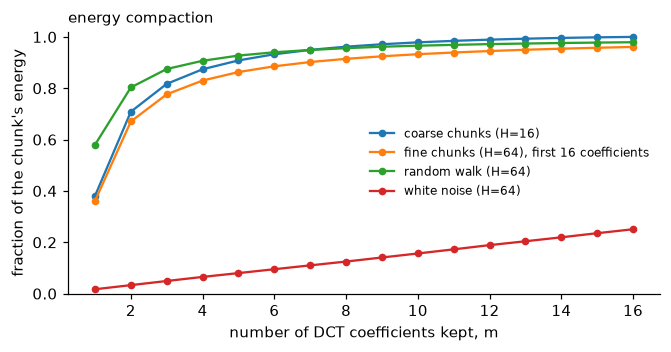

coarse: first 4 coefficients hold 87.4% of the energy, first 8 hold 96.2%
fine: first 4 coefficients hold 83.0% of the energy, first 8 hold 91.5%


In [5]:
def energy_curve(chunks):
    h = chunks.shape[1]
    coeff = torch.einsum("kt,ntd->nkd", dct_matrix(h), chunks)
    e = (coeff ** 2).sum(-1)                                               # (N, H) energy per coefficient, summed over dimensions
    e = e[e.sum(1) > 1e-9]                                                 # skip the all-zero (idle) chunks
    return (e.cumsum(1) / e.sum(1, keepdim=True)).mean(0).numpy()
rng_c = np.random.default_rng(0)
white = torch.from_numpy(rng_c.normal(size=(500, H_HI, 2)).astype(np.float32))
walk = white.cumsum(1)
plots.curves(list(range(1, 17)), {"coarse chunks (H=16)": energy_curve(chunks_lo), "fine chunks (H=64), first 16 coefficients": energy_curve(chunks_hi)[:16],
                                  "random walk (H=64)": energy_curve(walk)[:16], "white noise (H=64)": energy_curve(white)[:16]},
             "number of DCT coefficients kept, m", "fraction of the chunk's energy", "energy compaction", ylim=(0, 1.02))
for name, ch in (("coarse", chunks_lo), ("fine", chunks_hi)):
    c = energy_curve(ch)
    print(f"{name}: first 4 coefficients hold {c[3]:.1%} of the energy, first 8 hold {c[7]:.1%}")

Our demonstrations are smooth plans (a straight run then a stop), so **8 coefficients out of 64 hold 91 % of the energy** (and 4 hold 83 %) in the fine world, 96 % of it with 8 out of 16 at the coarse rate: that is the redundancy FAST removes. (Not 100 %: the abrupt *stop* at the end of the run needs high frequencies.) White noise has none to remove (its curve is a straight line), and a random walk (rough but still low-frequency-heavy) sits in between. FAST works because *robot actions are smooth*.

## Step 4: Quantisation: the only lossy step

Multiply the coefficients by `scale`, round, clip to `[−K, K]`. A larger `scale` keeps more detail and produces more non-zero integers (more tokens). We measure both sides of that trade: the **reconstruction error** and the **share of non-zero integers**.

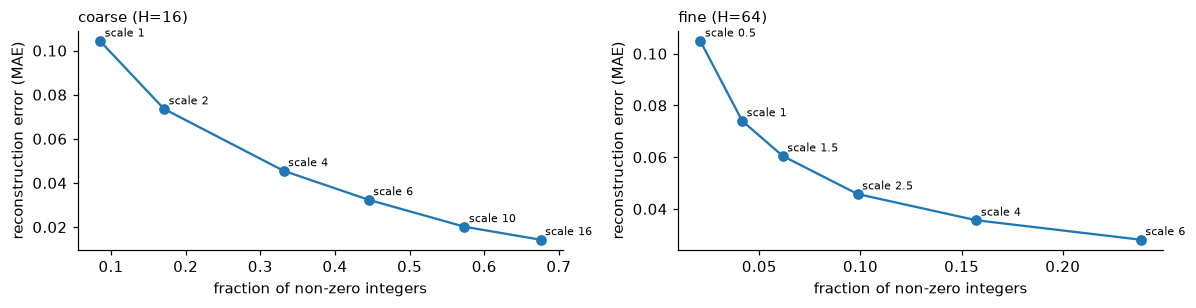

In [6]:
def quant_stats(chunks, scales, max_coefficient):
    h = chunks.shape[1]
    rows = []
    for sc in scales:
        t = FastActionTokenizer(h, 2, scale=sc, max_coefficient=max_coefficient)
        q = torch.stack([t.quantize(c) for c in chunks[:400]])
        rec = torch.stack([t.dequantize(x) for x in q])
        rows.append((sc, float((rec - chunks[:400]).abs().mean()), float((q != 0).float().mean())))
    return rows
fig, axes = plt.subplots(1, 2, figsize=(11, 2.9))
for ax, ch, scales, K, name in ((axes[0], chunks_lo, [1, 2, 4, 6, 10, 16], 40, "coarse (H=16)"), (axes[1], chunks_hi, [0.5, 1, 1.5, 2.5, 4, 6], 40, "fine (H=64)")):
    rows = quant_stats(ch, scales, K)
    ax.plot([r[2] for r in rows], [r[1] for r in rows], "o-")
    for sc, err, nz in rows:
        ax.annotate(f"scale {sc:g}", (nz, err), fontsize=7.5, xytext=(3, 3), textcoords="offset points")
    ax.set_xlabel("fraction of non-zero integers"); ax.set_ylabel("reconstruction error (MAE)"); ax.set_title(name, fontsize=9.5, loc="left"); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## Step 5: Flattening order, and what BPE does

**Order.** The integers form an `H × D` grid. FAST flattens it **frequency-major**: coefficient 0 of every dimension, then coefficient 1 of every dimension, …. The alternative is dimension-major (all of dimension 0, then dimension 1). Why does it matter? In an autoregressive model the *first* tokens must be the most informative (everything after is conditioned on them),
and with frequency-major order a truncated or corrupted tail loses only fine detail. We test this: decode only the first fraction `f` of the integers (the rest set to zero) and measure the error, for both orders.

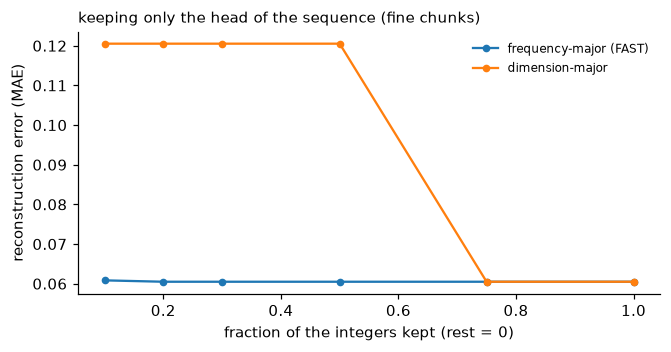

In [7]:
def truncation_error(chunks, order, fracs):
    h = chunks.shape[1]
    t = FastActionTokenizer(h, 2, scale=6.0 if h == H_LO else 1.5, max_coefficient=40, order=order)
    out = []
    for f in fracs:
        errs = []
        for c in chunks[:300]:
            sym = torch.tensor(t._symbols(t.quantize(c))) - t.max_coefficient
            sym[int(round(f * len(sym))):] = 0
            q = sym.view(h, 2) if order == "frequency" else sym.view(2, h).T
            errs.append(float((t.dequantize(q) - c).abs().mean()))
        out.append(np.mean(errs))
    return out
fracs = [0.1, 0.2, 0.3, 0.5, 0.75, 1.0]
plots.curves(fracs, {"frequency-major (FAST)": truncation_error(chunks_hi, "frequency", fracs), "dimension-major": truncation_error(chunks_hi, "dimension", fracs)},
             "fraction of the integers kept (rest = 0)", "reconstruction error (MAE)", "keeping only the head of the sequence (fine chunks)", ylim=None)

With frequency-major order the error is **already at its floor with the first 10 % of the sequence** (the low-frequency terms of *both* dimensions are there; everything after is zeros anyway); with dimension-major order the whole second dimension is missing until the half-way point and the error is twice as large. That is the property that makes the code **graceful** under a wrong or truncated tail.

**BPE.** The flattened sequence is mostly zeros, in long runs. *Byte-pair encoding* repeatedly finds the most frequent adjacent pair of symbols in a training corpus and replaces it with a new symbol: first `0 0 → A`, then `A A → B` (four zeros), and so on. We fit it on our chunks, read off the learned merges, check that decoding is **lossless**, and see how the token count falls with the number of merges.

first merges (token id → the integers it expands to):
    29 → a run of 2 zeros
    30 → a run of 4 zeros
    31 → a run of 8 zeros
    32 → a run of 16 zeros
    33 → a run of 32 zeros
    34 → a run of 64 zeros
    35 → [0, 1]
    36 → [0, -1]
lossless: decode(encode(chunk)) == dequantize(quantize(chunk)): True


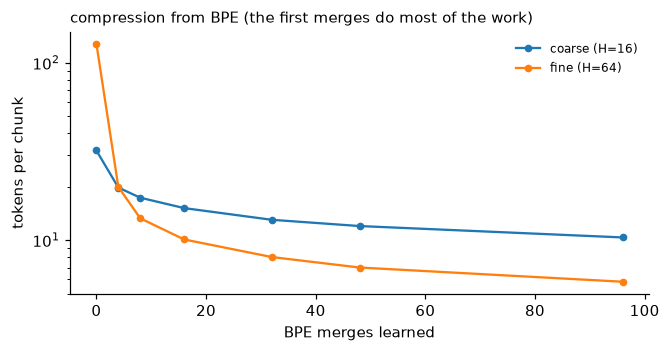

{'coarse (H=16)': [np.float64(32.0), np.float64(19.8), np.float64(17.3), np.float64(15.2), np.float64(13.0), np.float64(12.0), np.float64(10.4)], 'fine (H=64)': [np.float64(128.0), np.float64(20.0), np.float64(13.3), np.float64(10.1), np.float64(8.0), np.float64(7.0), np.float64(5.8)]} (0 merges = one token per integer: H·D)


In [8]:
def describe_merges(tok, n=8):
    # expand every merged symbol into the integers it stands for
    expand = {}
    for r, (a, b) in enumerate(tok.merges):
        new = tok.base_size + r
        left, right = expand.get(a, [a - tok.max_coefficient]), expand.get(b, [b - tok.max_coefficient])
        expand[new] = left + right
    return [(tok.base_size + r, expand[tok.base_size + r]) for r in range(min(n, len(tok.merges)))]

tok_hi = FastActionTokenizer(H_HI, 2, scale=1.5, max_coefficient=14, num_merges=48).fit(chunks_hi)
print("first merges (token id → the integers it expands to):")
for tid, ints in describe_merges(tok_hi):
    print(f"   {tid:3d} → " + (f"a run of {len(ints)} zeros" if set(ints) == {0} else str(ints)))
c = chunks_hi[[i for i in range(len(chunks_hi)) if chunks_hi[i].abs().sum() > 3.0][3]]
print("lossless: decode(encode(chunk)) == dequantize(quantize(chunk)):", torch.allclose(tok_hi.decode(tok_hi.encode(c)), tok_hi.dequantize(tok_hi.quantize(c)), atol=1e-6))
merges = [0, 4, 8, 16, 32, 48, 96]
curve = {}
for name, h, ch, sc, K in (("coarse (H=16)", H_LO, chunks_lo, 6.0, 40), ("fine (H=64)", H_HI, chunks_hi, 1.5, 14)):
    curve[name] = [np.mean([len(t.encode(x)) for x in ch[:300]]) for t in (FastActionTokenizer(h, 2, scale=sc, max_coefficient=K, num_merges=m).fit(ch) for m in merges)]
plots.curves(merges, curve, "BPE merges learned", "tokens per chunk", "compression from BPE (the first merges do most of the work)", logy=True)
print({k: [round(v, 1) for v in vs] for k, vs in curve.items()}, "(0 merges = one token per integer: H·D)")

The first merges are exactly the *runs of zeros* (`0 0`, then four zeros, then eight …), and the token count falls from `H·D` (128 for the fine chunks) to a few tens with a handful of merges, and keeps falling more slowly afterwards.

## Step 6: Tokens vs reconstruction error: FAST against the alternatives

Everything so far in one picture. For a **budget of tokens per chunk** what reconstruction error can each scheme reach?

* **per-step bins** (RT-2): `H·D` tokens, whatever the number of bins (varying the bins only changes the error);
* **sub-sampled bins** (the obvious cheaper baseline): keep every `k`-th action, bin it, and linearly **interpolate** the rest: `H·D/k` tokens;
* **FAST**: sweep `scale` and the number of merges.

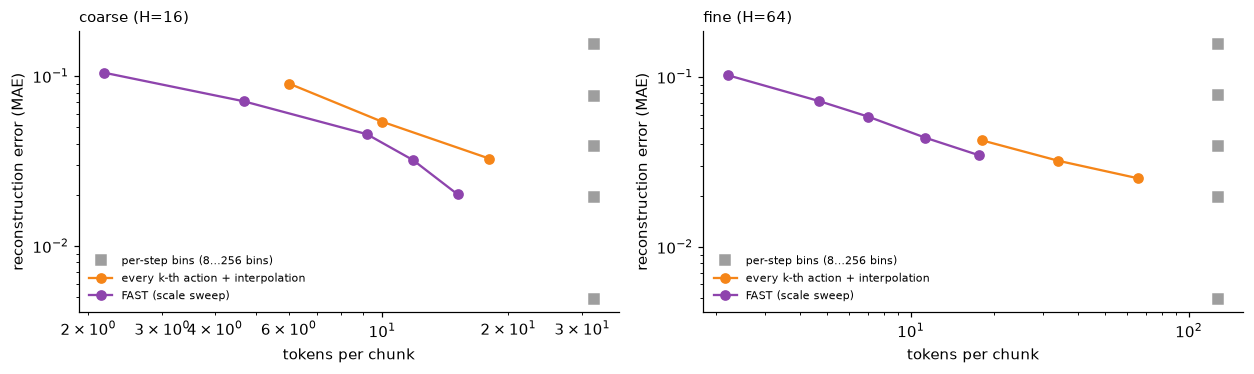

In [9]:
def bins_error(ch, nb):
    b = ActionBinner(nb, -1.5, 1.5)
    return float((b.roundtrip(ch) - ch).abs().mean())

def subsample_error(ch, k, nb=64):
    h = ch.shape[1]
    idx = list(range(0, h, k)) + ([h - 1] if (h - 1) % k else [])
    b = ActionBinner(nb, -1.5, 1.5)
    kept = b.roundtrip(ch[:, idx])
    rec = torch.from_numpy(np.stack([np.stack([np.interp(np.arange(h), idx, kept[n, :, d].numpy()) for d in range(2)], 1) for n in range(len(ch))])).float()
    return float((rec - ch).abs().mean()), len(idx) * 2

def fast_frontier(ch, h, scales, K):
    pts = []
    for sc in scales:
        t = FastActionTokenizer(h, 2, scale=sc, max_coefficient=K, num_merges=48).fit(ch[:800])
        pts.append((np.mean([len(t.encode(x)) for x in ch[800:1100]]), np.mean([float((t.decode(t.encode(x)) - x).abs().mean()) for x in ch[800:1100]])))
    return pts
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.5))
for ax, ch, h, scales, K, name in ((axes[0], chunks_lo, H_LO, [1, 2, 4, 6, 10], 40, "coarse (H=16)"), (axes[1], chunks_hi, H_HI, [0.5, 1, 1.5, 2.5, 4], 40, "fine (H=64)")):
    ax.plot([2 * h] * 5, [bins_error(ch, nb) for nb in (8, 16, 32, 64, 256)], "s", color="#9e9e9e", label="per-step bins (8…256 bins)")
    sub = [subsample_error(ch, k) for k in (2, 4, 8)]
    ax.plot([s[1] for s in sub], [s[0] for s in sub], "o-", color="#f58518", label="every k-th action + interpolation")
    fr = fast_frontier(ch, h, scales, K)
    ax.plot([p[0] for p in fr], [p[1] for p in fr], "o-", color="#8e44ad", label="FAST (scale sweep)")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("tokens per chunk"); ax.set_ylabel("reconstruction error (MAE)"); ax.set_title(name, fontsize=9.5, loc="left")
    ax.spines[["top", "right"]].set_visible(False); ax.legend(fontsize=7.5, frameon=False)
plt.tight_layout(); plt.show()

**Reading the frontier** (lower-left is better). Per-step bins sit at a fixed, large token count (32 or 128) whatever the number of bins. Sub-sampling and FAST both reduce tokens; FAST reaches the same error with **about half as many tokens as sub-sampling** (e.g. at an error of 0.04 on the fine chunks: ≈ 11 FAST tokens against ≈ 20), and with **an order of magnitude fewer than per-step bins** (≈ 128 tokens for any error below 0.15).
The advantage over sub-sampling is real but modest: the bulk of the gain over bins comes from *not coding a smooth signal sample by sample*, which sub-sampling also does; FAST adds a better basis (no interpolation error at corners) and entropy coding of the zeros. The number of FAST tokens barely grows when the same trajectory is sampled four times as finely, while per-step bins grow 4× with it.

# Part 3: Does it help the policy?

## Step 7: One VLM, two tokenisations, two control rates

We fine-tune the same VLM to emit (a) per-step **bin** tokens or (b) **FAST** tokens (+ `<eos>`), at the coarse and the fine control rate, and run it closed loop. Same demonstrations, same optimiser, same number of steps per setting. (The VLM gets a longer context so that the 128-token bin chunks fit.)

In [10]:
vocab = PiVocabulary(fast_size=256)
torch.manual_seed(0)
vlm = ToyVLM(VLMConfig(max_len=192), vocab)
pre = VLMPretrainer(vlm, world); pre.fit(1500)
print(f"VLM pre-trained in {pre.history.seconds:.0f} s (answer accuracy {np.mean(pre.history.accuracy[-50:]):.2f})")
tok_lo = FastActionTokenizer(H_LO, 2, scale=6.0, max_coefficient=12, num_merges=48).fit(chunks_lo)
tok_hi = FastActionTokenizer(H_HI, 2, scale=1.5, max_coefficient=14, num_merges=48).fit(chunks_hi)
scen_lo, scen_hi = make_embodied_scenarios(gen, "point2d", 96, seed=123), make_embodied_scenarios(hf_gen, "point2d", 96, seed=123)
ev_lo, ev_hi = EmbodiedEvaluator(world, H_LO, H_LO // 2, 50), EmbodiedEvaluator(hf_world, H_HI, H_HI // 2, 200)
def ms(fn, reps=8):
    fn(); t0 = time.perf_counter()
    for _ in range(reps):
        fn()
    return 1000 * (time.perf_counter() - t0) / reps

results = {}
def run(setting, scheme, checkpoints, seed=0):
    data, tok, ev, scen, h = (data_lo, tok_lo, ev_lo, scen_lo, H_LO) if setting == "coarse" else (data_hi, tok_hi, ev_hi, scen_hi, H_HI)
    torch.manual_seed(seed)
    m = FastActionPolicy(vlm, tok, max_tokens=80) if scheme == "FAST" else AutoregressiveActionPolicy(vlm, ARConfig(chunk_size=h))
    tr = PiTrainer(m, data, batch_size=32 if setting == "fine" else 64, lr=2e-3, grad_clip=10.0, seed=seed)
    curve, done = [], 0
    for target in checkpoints:                       # train a little, evaluate, continue: a success-vs-steps curve
        tr.fit(target - done); done = target; m.eval()
        curve.append((target, ev.run(lambda b: m.sample_actions(b), scen).success_rate)); m.train()
    m.eval()
    one = data.sample(1, np.random.default_rng(2))
    n_tok = m.mean_tokens(data.sample(64, np.random.default_rng(3)).actions) if scheme == "FAST" else 2 * h
    results[(setting, scheme, seed)] = dict(success=curve[-1][1], curve=curve, tokens=n_tok, ms=ms(lambda: m.sample_actions(one)), train_s=tr.history.seconds,
                                            tok_acc=float(np.mean(tr.history.series("token_acc")[-50:])), model=m)
    x = results[(setting, scheme, seed)]
    print(f"{setting:6s} {scheme:5s} seed {seed}: success at {[c[0] for c in curve]} steps = {[round(c[1], 2) for c in curve]} | tokens/chunk {x['tokens']:5.1f} | {x['ms']:5.1f} ms/chunk | token accuracy {x['tok_acc']:.2f} | {x['train_s']:.0f} s", flush=True)
run("coarse", "bins", [1500, 3000]); run("coarse", "FAST", [1500, 3000])

VLM pre-trained in 132 s (answer accuracy 0.93)


coarse bins  seed 0: success at [1500, 3000] steps = [0.0, 0.4] | tokens/chunk  32.0 |  75.6 ms/chunk | token accuracy 0.68 | 502 s


coarse FAST  seed 0: success at [1500, 3000] steps = [0.04, 0.15] | tokens/chunk  13.5 |  26.1 ms/chunk | token accuracy 0.67 | 467 s


In [11]:
# the fine control rate is the hard case for bins and the slow case for everyone: train longer and watch success appear
run("fine", "bins", [2000, 4000, 6000]); run("fine", "FAST", [2000, 4000, 6000], seed=0); run("fine", "FAST", [2000, 4000, 6000], seed=1)

fine   bins  seed 0: success at [2000, 4000, 6000] steps = [0.0, 0.03, 0.41] | tokens/chunk 128.0 | 222.5 ms/chunk | token accuracy 0.71 | 1362 s


fine   FAST  seed 0: success at [2000, 4000, 6000] steps = [0.03, 0.03, 0.14] | tokens/chunk   8.4 |  20.0 ms/chunk | token accuracy 0.72 | 462 s


fine   FAST  seed 1: success at [2000, 4000, 6000] steps = [0.02, 0.24, 0.86] | tokens/chunk   8.4 |  20.2 ms/chunk | token accuracy 0.78 | 473 s


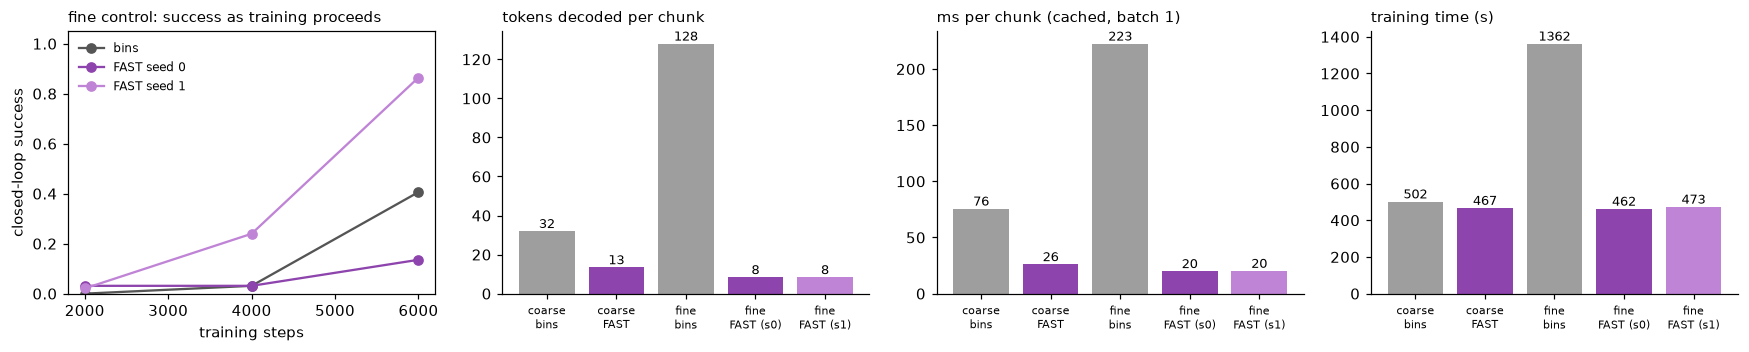

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.3), facecolor="white")
for key, col, name in ((("fine", "bins", 0), "#555555", "bins"), (("fine", "FAST", 0), "#8e44ad", "FAST seed 0"), (("fine", "FAST", 1), "#c084d6", "FAST seed 1")):
    c = results[key]["curve"]
    axes[0].plot([p[0] for p in c], [p[1] for p in c], "o-", color=col, label=name)
axes[0].set_xlabel("training steps"); axes[0].set_ylabel("closed-loop success"); axes[0].set_title("fine control: success as training proceeds", fontsize=9.5, loc="left"); axes[0].legend(fontsize=8, frameon=False); axes[0].set_ylim(0, 1.05)
labels = ["coarse\nbins", "coarse\nFAST", "fine\nbins", "fine\nFAST (s0)", "fine\nFAST (s1)"]
keys = [("coarse", "bins", 0), ("coarse", "FAST", 0), ("fine", "bins", 0), ("fine", "FAST", 0), ("fine", "FAST", 1)]
for ax, (field, title, fmt) in zip(axes[1:], (("tokens", "tokens decoded per chunk", "{:.0f}"), ("ms", "ms per chunk (cached, batch 1)", "{:.0f}"), ("train_s", "training time (s)", "{:.0f}"))):
    vals = [results[k][field] for k in keys]
    ax.bar(range(len(keys)), vals, color=["#9e9e9e", "#8e44ad", "#9e9e9e", "#8e44ad", "#c084d6"])
    for i, v in enumerate(vals):
        ax.text(i, v, fmt.format(v), ha="center", va="bottom", fontsize=8.5)
    ax.set_xticks(range(len(keys))); ax.set_xticklabels(labels, fontsize=7.5); ax.set_title(title, fontsize=9.5, loc="left"); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

**The result, and it is not one-sided.**

* **Coarse control (`H = 16`): FAST does not win on success.** It uses 2.4× fewer tokens (13.5 vs 32) and decodes about 3× faster per chunk, but at the same training budget the *bin* policy is the better one (0.40 vs 0.15 after 3000 steps). The sequence of 32 bins is highly copyable *and the copy is nearly the right answer* (a straight run at constant velocity), so binning is not hard here; FAST's tokens are less regular
  (rare merged tokens, long zero runs) and a single wrong coefficient perturbs the whole chunk.
* **Fine control (`H = 64`): FAST wins by an order of magnitude on *cost*.** 8 tokens instead of 128 (15× fewer), **≈ 20 ms instead of ≈ 220 ms per chunk** (11×), and 3× less wall-clock training time for the same number of steps (the bin policy's sequences are 16× longer). Its *success* after 6000 steps is, however, **seed-dependent**: the bin policy reaches 0.41; FAST reaches 0.86 with one seed and 0.14 with another, because in all
  these runs success appears suddenly (see the left plot: nothing for the first 2000-4000 steps, then a jump) and the second FAST seed has not made its jump yet. So *sample efficiency is not what separates the two here* (in the FAST paper the training-efficiency gain is measured at scale, on real high-frequency data, against much stronger baselines); **cost per chunk is**, and it grows with the control frequency for bins but not for FAST,
  because the number of FAST tokens depends on the *complexity* of the motion, not on how finely it is sampled.
* **Latency** follows the token count at both rates.

## Step 8: Failure modes: malformed sequences

A tokeniser that compresses this much has a price: an autoregressive model can emit a token sequence that does **not** decode to a full chunk (too few or too many coefficients). We sample the fine-rate FAST policy at temperature 1 and count, using `FastActionTokenizer.is_valid`. (`decode` is robust to this: it pads with zeros or truncates, as the paper does,
but a padded chunk is a degraded one.)

In [13]:
policy = results[("fine", "FAST", 0)]["model"]
obs = EmbodiedEvaluator(hf_world, H_HI, H_HI // 2, 1).observe(scen_hi, np.stack([s.scene.robot for s in scen_hi])[:, None, :].astype(np.float32), np.full(len(scen_hi), -1.0), 0)
valid = {}
for temp in (0.0, 0.5, 1.0, 1.5):
    policy.sample_actions(obs, temperature=temp)
    valid[temp] = float(np.mean([tok_hi.is_valid(row) for row in policy.last_tokens]))
print("fraction of sampled token sequences that decode to a complete chunk:", {t: round(v, 2) for t, v in valid.items()})

fraction of sampled token sequences that decode to a complete chunk: {0.0: 1.0, 0.5: 0.99, 1.0: 0.88, 1.5: 0.73}


Greedy decoding always produced a valid sequence here (100 %); at temperature 1 about 88 % are valid and at 1.5 only 73 %: hotter sampling produces more malformed ones. In practice FAST systems decode greedily (or at low temperature) and treat the rare malformed output as a no-op / re-query. This is one reason the real π0-FAST needs a *much* larger and better-pretrained VLM than a toy: the model must produce long, exactly-formed token sequences.

## Step 9: Where FAST sits, and recap

| | tokens per chunk | continuous? | decode | notes |
|---|---|---|---|---|
| per-step bins (RT-2, OpenVLA) | `H·D` | no | sequential, `H·D` passes | simplest; bad at high rate |
| **FAST** (π0-FAST) | ≈ 30-60 for a 50×7 chunk, depends on the motion | no (lossy rounding) | sequential, tens of passes | universal **FAST+** tokenizer, vocabulary 1024 |
| flow-matching expert (π0, SmolVLA, GR00T) | none | yes | `K` ≈ 4-10 parallel steps | needs an extra action expert |
| OpenVLA-OFT | none | yes (L1 head) | **one** pass (parallel decoding) | not a tokenizer: a different head and fine-tuning recipe |

**Take-aways.** (1) FAST = DCT → quantise → flatten low-frequency first → BPE; the only loss is the rounding; decoding is exact. (2) It works because robot actions are smooth: the DCT concentrates the energy (Step 3), and the frequency-major order makes the head of the sequence the informative part (Step 5).
(3) Per-step binning has a *cost* problem at high control rates (`H·D` sequential tokens, 95 % of them copies; Step 1, Step 7), and a plausible *learning* problem too (the loss rewards copying), which this toy shows only weakly: success is seed-dependent. (4) FAST is **not** free: at a coarse rate bins can be better, rare tokens are harder to learn, and malformed sequences must be handled (Steps 7-8). (5) The three other ways to a fast VLA (a flow expert, parallel decoding with a continuous head, smaller VLMs) attack
the *same* bottleneck, sequential decoding, from a different side.

### 🧪 Exercises
1. In Step 4 pick `scale` so that the reconstruction error equals the 256-bin error; how many tokens does FAST then need (Step 6 frontier)?
2. Fit the tokenizer on *noisy* demonstrations (the `sloppy` style in `pi_family.toy.episodes`): how does compression degrade as high-frequency content appears (Step 3 curve)?
3. Use `order="dimension"` in `FastActionTokenizer` for the policy of Step 7: does the policy learn faster or slower?
4. Add a third setting `H = 32` and plot success vs control frequency for bins and FAST: where do the curves cross?
5. Replace the learned BPE by a *fixed* universal tokenizer fitted on the fine chunks and use it on the coarse chunks (resampled): how much compression is lost? (This is the FAST+ idea.)